<a href="https://colab.research.google.com/github/melekyakin/StockPriceForecastingLSTM/blob/main/StockPriceForecastingLSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Stock Price Forecasting with LSTM**

**Business Problem**

· Date: Represents the date of the relevant trading day.

· Open: Represents the opening price of the stock for the relevant trading day.

· High: Represents the highest price for the relevant trading day.

· Low: Represents the lowest price for the relevant trading day.

· Close: Represents the closing price of the stock on the relevant trading day.

· Adj Close: Represents the adjusted closing price of the stock for the relevant trading day.

· Volume: Represents the trading volume for the relevant trading day.

Translated with DeepL.com (free version)

Dataset: https://www.kaggle.com/timoboz/tesla-stock-data-from-2010-to-*2020*

In [54]:
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

In [55]:
# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
CSV_PATH = "TSLA.csv"
LOOKBACK = 20          # number of past days used to predict the next day
TEST_SIZE = 0.20       # last 20% of the series -> test
VAL_SIZE = 0.15        # last 15% of the training part -> validation
EPOCHS = 100
BATCH_SIZE = 32
SEED = 42

tf.keras.utils.set_random_seed(SEED)


In [56]:
# ----------------------------------------------------------------------------
# Data loading
# ----------------------------------------------------------------------------
def load_data(path: str) -> pd.DataFrame:
    """Load the CSV. On Google Colab, prompt for an upload if the file is missing."""
    if not os.path.exists(path):
        try:
            from google.colab import files  # only available on Colab
            files.upload()
        except ImportError:
            raise FileNotFoundError(
                f"{path} not found. Download it from Kaggle and place it next to this script."
            )
    return pd.read_csv(path)


def check_df(dataframe: pd.DataFrame, head: int = 5) -> None:
    print("#################### Shape ####################")
    print(dataframe.shape)
    print("#################### Types ####################")
    print(dataframe.dtypes)
    print("#################### Head ####################")
    print(dataframe.head(head))
    print("#################### Tail ####################")
    print(dataframe.tail(head))
    print("#################### NA ####################")
    print(dataframe.isnull().sum())
    print("#################### Quantiles ####################")
    print(dataframe.quantile([0, 0.05, 0.50, 0.95, 0.99, 1], numeric_only=True).T)


def create_windows(data: np.ndarray, lookback: int):
    """
    Sliding windows over a scaled 1-D series.

    Returns
    -------
    X : (n_samples, lookback, 1)
    y : (n_samples, 1)
    target_idx : positions (in the full series) of each target value
    """
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i, 0])
        y.append(data[i, 0])
    X = np.array(X).reshape(-1, lookback, 1)
    y = np.array(y).reshape(-1, 1)
    target_idx = np.arange(lookback, len(data))
    return X, y, target_idx


def regression_report(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)
    print(f"{name:<22} RMSE: {rmse:8.3f} | MAE: {mae:8.3f} | MAPE: {mape:6.2f}%")
    return {"rmse": rmse, "mae": mae, "mape": mape}


#################### Shape ####################
(2416, 7)
#################### Types ####################
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
#################### Head ####################
         Date       Open   High        Low      Close  Adj Close    Volume
0  2010-06-29  19.000000  25.00  17.540001  23.889999  23.889999  18766300
1  2010-06-30  25.790001  30.42  23.299999  23.830000  23.830000  17187100
2  2010-07-01  25.000000  25.92  20.270000  21.959999  21.959999   8218800
3  2010-07-02  23.000000  23.10  18.709999  19.200001  19.200001   5139800
4  2010-07-06  20.000000  20.00  15.830000  16.110001  16.110001   6866900
#################### Tail ####################
            Date        Open        High         Low       Close   Adj Close  \
2411  2020-01-28  568.489990  576.809998  558.080017  566.900024  566.900024   
2412  2020-01-29  575.690002 

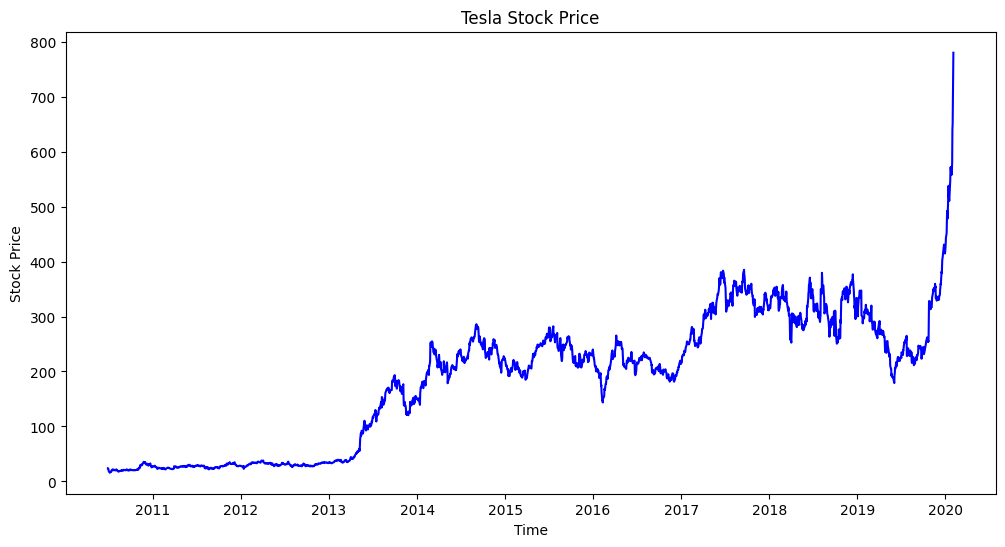

Train: 0-1642 | Val: 1643-1932 | Test: 1933-2415
(1623, 20, 1) (290, 20, 1) (483, 20, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100

Epoch 1: val_loss improved from None to 0.01598, saving model to mymodel.keras

Epoch 1: finished saving model to mymodel.keras
51/51 - 3s - 56ms/step - loss: 0.0148 - val_loss: 0.0160
Epoch 2/100

Epoch 2: val_loss did not improve from 0.01598
51/51 - 1s - 13ms/step - loss: 0.0142 - val_loss: 0.0285
Epoch 3/100

Epoch 3: val_loss improved from 0.01598 to 0.00700, saving model to mymodel.keras

Epoch 3: finished saving model to mymodel.keras
51/51 - 2s - 30ms/step - loss: 0.0046 - val_loss: 0.0070
Epoch 4/100

Epoch 4: val_loss improved from 0.00700 to 0.00601, saving model to mymodel.keras

Epoch 4: finished saving model to mymodel.keras
51/51 - 1s - 15ms/step - loss: 0.0036 - val_loss: 0.0060
Epoch 5/100

Epoch 5: val_loss did not improve from 0.00601
51/51 - 1s - 10ms/step - loss: 0.0034 - val_loss: 0.0086
Epoch 6/100

Epoch 6: val_loss improved from 0.00601 to 0.00476, saving model to mymodel.keras

Epoch 6: finished saving model to mymodel.keras
51/51 - 1s - 13ms/step

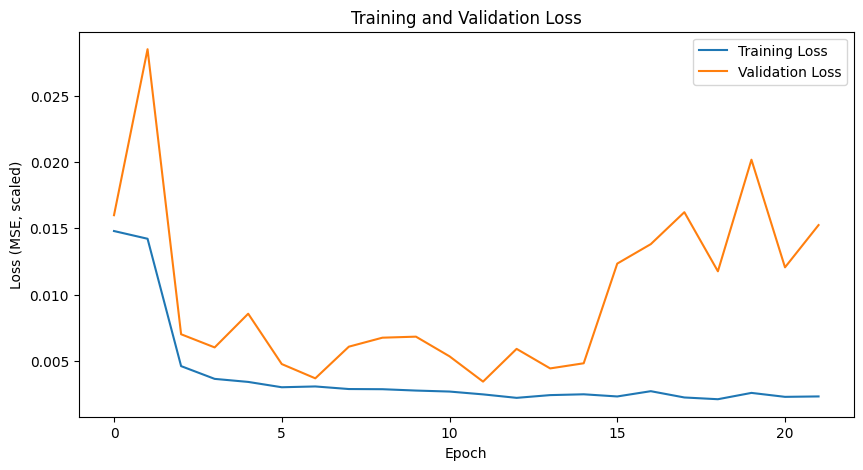


=========== Results (price scale) ===========
LSTM - Train           RMSE:    7.684 | MAE:    5.868 | MAPE:   7.57%
LSTM - Validation      RMSE:   15.839 | MAE:   12.898 | MAPE:   3.95%
LSTM - Test            RMSE:   26.090 | MAE:   16.583 | MAPE:   4.98%
Naive baseline - Test  RMSE:   12.386 | MAE:    7.637 | MAPE:   2.46%

LSTM does NOT beat the naive baseline on the test set.


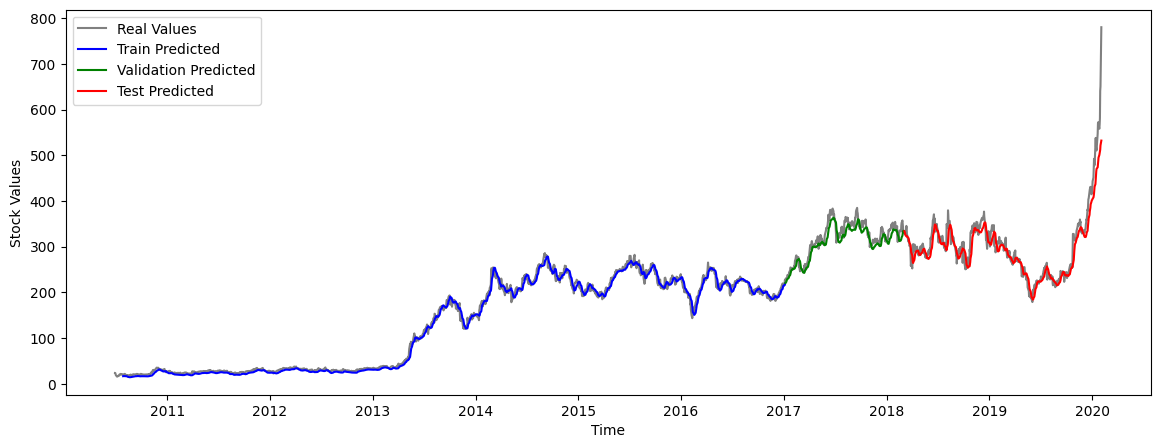

In [57]:
# ----------------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------------
def main():
    df = load_data(CSV_PATH)
    check_df(df)

    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").set_index("Date")
    close = df[["Close"]].astype("float32")

    print("Min date:", close.index.min())
    print("Max date:", close.index.max())

    plt.figure(figsize=(12, 6))
    plt.plot(close["Close"], color="blue")
    plt.ylabel("Stock Price")
    plt.title("Tesla Stock Price")
    plt.xlabel("Time")
    plt.show()

    # --- Chronological split points (positions in the full series) -----------
    n = len(close)
    test_start = int(round(n * (1 - TEST_SIZE)))
    val_start = int(round(test_start * (1 - VAL_SIZE)))
    print(f"Train: 0-{val_start - 1} | Val: {val_start}-{test_start - 1} | Test: {test_start}-{n - 1}")

    # --- Scale: fit ONLY on the training part ---------------------------------
    scaler = MinMaxScaler(feature_range=(0, 1))
    scaler.fit(close.values[:val_start])
    scaled = scaler.transform(close.values)  # same scale for all splits

    # --- Windows over the whole series, then split by target position --------
    X_all, y_all, idx = create_windows(scaled, LOOKBACK)

    train_mask = idx < val_start
    val_mask = (idx >= val_start) & (idx < test_start)
    test_mask = idx >= test_start

    X_train, y_train = X_all[train_mask], y_all[train_mask]
    X_val, y_val = X_all[val_mask], y_all[val_mask]
    X_test, y_test = X_all[test_mask], y_all[test_mask]
    print(X_train.shape, X_val.shape, X_test.shape)

    # --- Model -----------------------------------------------------------------
    model = Sequential([
        LSTM(50, input_shape=(LOOKBACK, 1)),  # default tanh activation
        Dropout(0.2),
        Dense(1),
    ])
    model.compile(loss="mean_squared_error", optimizer="adam")
    model.summary()

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=10, mode="min",
                      restore_best_weights=True, verbose=1),
        ModelCheckpoint("mymodel.keras", monitor="val_loss", mode="min",
                        save_best_only=True, verbose=1),
    ]

    history = model.fit(
        X_train, y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        callbacks=callbacks,
        shuffle=False,  # keep temporal order
        verbose=2,
    )

    plt.figure(figsize=(10, 5))
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.legend(loc="upper right")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE, scaled)")
    plt.title("Training and Validation Loss")
    plt.show()

    # --- Evaluation (test set used only here) ----------------------------------
    pred_train = scaler.inverse_transform(model.predict(X_train, verbose=0))
    pred_val = scaler.inverse_transform(model.predict(X_val, verbose=0))
    pred_test = scaler.inverse_transform(model.predict(X_test, verbose=0))

    true_train = scaler.inverse_transform(y_train)
    true_val = scaler.inverse_transform(y_val)
    true_test = scaler.inverse_transform(y_test)

    # Naive baseline: tomorrow's price = today's price
    prices = close["Close"].values.astype("float64")
    test_idx = idx[test_mask]
    naive_test = prices[test_idx - 1].reshape(-1, 1)

    print("\n=========== Results (price scale) ===========")
    regression_report("LSTM - Train", true_train, pred_train)
    regression_report("LSTM - Validation", true_val, pred_val)
    lstm_test = regression_report("LSTM - Test", true_test, pred_test)
    naive = regression_report("Naive baseline - Test", true_test, naive_test)

    if lstm_test["rmse"] < naive["rmse"]:
        print("\nLSTM beats the naive baseline on the test set.")
    else:
        print("\nLSTM does NOT beat the naive baseline on the test set.")

    # --- Plot -----------------------------------------------------------------
    dates = close.index
    plt.figure(figsize=(14, 5))
    plt.plot(dates, prices, label="Real Values", color="gray")
    plt.plot(dates[idx[train_mask]], pred_train.ravel(), color="blue", label="Train Predicted")
    plt.plot(dates[idx[val_mask]], pred_val.ravel(), color="green", label="Validation Predicted")
    plt.plot(dates[test_idx], pred_test.ravel(), color="red", label="Test Predicted")
    plt.xlabel("Time")
    plt.ylabel("Stock Values")
    plt.legend()
    plt.show()


if __name__ == "__main__":
    main()
